## Exercício: Usando LSTMs para Classificar o Conjunto de Dados 20 Newsgroups
O conjunto de dados 20 Newsgroups é um problema de classificação bem conhecido. O objetivo é classificar de qual grupo de notícias veio uma postagem específica. Os 20 grupos possíveis são:

`comp.graphics`<br>
`comp.os.ms-windows.misc`<br>
`comp.sys.ibm.pc.hardware`<br>
`comp.sys.mac.hardware`<br>
`comp.windows.x`<br>
`rec.autos`<br>
`rec.motorcycles`<br>
`rec.sport.baseball`<br>
`rec.sport.hockey`<br>
`sci.crypt`<br>
`sci.electronics`<br>
`sci.med`<br>
`sci.space`<br>
`misc.forsale`<br>
`talk.politics.misc`<br>
`talk.politics.guns`<br>
`talk.politics.mideast`<br>
`talk.religion.misc`<br>
`alt.atheism`<br>
`soc.religion.christian`<br>

Como você pode ver, alguns pares de grupos podem ser bastante semelhantes, enquanto outros são muito diferentes.

Os dados são fornecidos como um conjunto de treinamento designado de tamanho 11314 e conjunto de teste de tamanho 7532. As 20 categorias são representadas em proporções aproximadamente iguais, portanto a precisão de base é cerca de 5%.

Para começar, revise o código abaixo. Isso irá guiá-lo pelos conceitos básicos de carregar os dados do 20 newsgroups, carregar os dados do GloVe, construir a matriz de embeddings de palavras e construir o modelo LSTM.

Depois de construirmos o primeiro modelo LSTM, será sua vez de construir um e experimentar com os parâmetros.

In [1]:
# Preliminares

from __future__ import absolute_import, division, print_function  # Compatibilidade Python 2/3

import warnings
warnings.filterwarnings("ignore")

import numpy as np

import tensorflow.keras as keras
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, Dropout, SpatialDropout1D
from tensorflow.keras.layers import LSTM, SimpleRNN
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.initializers import Identity, RandomNormal
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.datasets import fetch_20newsgroups

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [70]:
max_features = 20000
seq_length = 150  # 30 pra 150 pra não cortar o assunto principal dos textos
batch_size = 64   # 64 pra rodar mais rapido

In [71]:
# Baixar os dados do 20 newsgroups - já existe um conjunto designado de "train" e "test"

newsgroups_train = fetch_20newsgroups(subset='train')
newsgroups_test = fetch_20newsgroups(subset='test')

In [72]:
len(newsgroups_train.data), len(newsgroups_test.data)

(11314, 7532)

In [73]:
tokenizer = Tokenizer(num_words=max_features)
tokenizer.fit_on_texts(newsgroups_train.data)

In [74]:
sequences_train = tokenizer.texts_to_sequences(newsgroups_train.data)
sequences_test = tokenizer.texts_to_sequences(newsgroups_test.data)

In [75]:
word_index = tokenizer.word_index
print('Encontrados %s tokens únicos.' % len(word_index))

Encontrados 134142 tokens únicos.


In [76]:
x_train = pad_sequences(sequences_train, maxlen=seq_length)
x_test = pad_sequences(sequences_test, maxlen=seq_length)

In [52]:
x_train

array([[   0,    0,    0, ...,  167,  101,  206],
       [   0,    0,    0, ...,   14, 7472,  195],
       [4726,   24,    7, ..., 6523, 2254, 1777],
       ...,
       [   0,    0,    0, ...,    5, 4531,  224],
       [   0,    0,    0, ..., 1187,  123, 1057],
       [   0,    0,    0, ...,  181,   41, 4767]],
      shape=(11314, 150), dtype=int32)

In [77]:
y_train = keras.utils.to_categorical(np.asarray(newsgroups_train.target))
y_test = keras.utils.to_categorical(np.asarray(newsgroups_test.target))

In [54]:
y_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(11314, 20))

Usaremos os vetores de palavras pré-treinados GloVe. Se você ainda não o fez, por favor baixe-os usando este link:
(NOTA: isso iniciará o download de um arquivo de 822MB)

http://nlp.stanford.edu/data/glove.6B.zip

Em seguida, descompacte o arquivo e preencha seu caminho local para o arquivo na célula de código abaixo.

Usaremos o arquivo `glove.6B.100d.txt`

In [12]:
# -nc evita baixar novamente se o zip já existir; -n evita travar perguntando se deseja sobrescrever
!wget -nc https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip
!unzip -n -j glove.6B.zip glove.6B.100d.txt

--2026-11-18 19:13:33--  https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip
Resolving huggingface.co (huggingface.co)... 99.86.101.36, 99.86.101.39, 99.86.101.56, ...
Connecting to huggingface.co (huggingface.co)|99.86.101.36|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/621ffdc136468d709f18095d/ded22944ac944002f423d1cdb83de044851330e1a7fe19d74dc59ffa632ad294?user_id=public&X-Xet-Cas-Uid=public&xip=WoS7sN5iHwc&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27glove.6B.zip%3B+filename%3D%22glove.6B.zip%22%3B&response-content-type=application%2Fzip&Expires=1795032813&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjIxZmZkYzEzNjQ2OGQ3MDlmMTgwOTVkL2RlZDIyOTQ0YWM5NDQwMDJmNDIzZDFjZGI4M2RlMDQ0ODUxMzMwZTFhN2ZlMTlkNzRkYzU5ZmZhNjMyYWQyOTRcXD91c2VyX2lkPXB1YmxpYyZYLVhldC1DYXMtVWlkPXB1YmxpYyZ4aXA9V29TN3NONWlId2MmcmVzcG9uc2UtY29udGVudC1kaXNwb3NpdGlvbj0qJ

In [13]:
embeddings_index = {}
f = open('glove.6B.100d.txt', encoding='utf-8')
for line in f:
    values = line.split()
    word = values[0]
    coefs = np.asarray(values[1:], dtype='float32')
    embeddings_index[word] = coefs
f.close()

print('Encontrados %s vetores de palavras.' % len(embeddings_index))

Encontrados 400001 vetores de palavras.


Vamos apenas observar um embedding de palavra

In [55]:
dog_vec = embeddings_index['dog']
dog_vec

array([ 0.30817  ,  0.30938  ,  0.52803  , -0.92543  , -0.73671  ,
        0.63475  ,  0.44197  ,  0.10262  , -0.09142  , -0.56607  ,
       -0.5327   ,  0.2013   ,  0.7704   , -0.13983  ,  0.13727  ,
        1.1128   ,  0.89301  , -0.17869  , -0.0019722,  0.57289  ,
        0.59479  ,  0.50428  , -0.28991  , -1.3491   ,  0.42756  ,
        1.2748   , -1.1613   , -0.41084  ,  0.042804 ,  0.54866  ,
        0.18897  ,  0.3759   ,  0.58035  ,  0.66975  ,  0.81156  ,
        0.93864  , -0.51005  , -0.070079 ,  0.82819  , -0.35346  ,
        0.21086  , -0.24412  , -0.16554  , -0.78358  , -0.48482  ,
        0.38968  , -0.86356  , -0.016391 ,  0.31984  , -0.49246  ,
       -0.069363 ,  0.018869 , -0.098286 ,  1.3126   , -0.12116  ,
       -1.2399   , -0.091429 ,  0.35294  ,  0.64645  ,  0.089642 ,
        0.70294  ,  1.1244   ,  0.38639  ,  0.52084  ,  0.98787  ,
        0.79952  , -0.34625  ,  0.14095  ,  0.80167  ,  0.20987  ,
       -0.86007  , -0.15308  ,  0.074523 ,  0.40816  ,  0.0192

In [56]:
## Isso cria uma matriz onde a i-ésima linha fornece o embedding de palavra para a palavra representada pelo inteiro i.
## Essencialmente, esses serão os "pesos" para a Camada de Embedding
## Em vez de aprender os pesos, usaremos esses e "congelaremos" a camada

embedding_matrix = np.zeros((len(word_index) + 1, 100))
for word, i in word_index.items():
    embedding_vector = embeddings_index.get(word)
    if embedding_vector is not None:
        # palavras não encontradas no índice de embeddings serão todas zeros.
        embedding_matrix[i] = embedding_vector

In [57]:
embedding_matrix.shape

(105373, 100)

In [58]:
import matplotlib.pyplot as plt

def plot_loss_accuracy(history):
    fig = plt.figure(figsize=(12, 6))
    ax = fig.add_subplot(1, 2, 1)
    ax.plot(history.history["loss"],'r-x', marker='.', label="Perda de Treino")
    ax.plot(history.history["val_loss"],'b-x', marker='.', label="Perda de Validação")
    ax.legend()
    ax.set_title('perda cross_entropy')
    ax.grid(True)


    ax = fig.add_subplot(1, 2, 2)
    ax.plot(history.history["accuracy"],'r', marker='.', label="Precisão de Treino")
    ax.plot(history.history["val_accuracy"],'b', marker='.', label="Precisão de Validação")
    ax.legend()
    ax.set_title('precisão')
    ax.grid(True)

## Camada LSTM
`keras.layers.recurrent.LSTM(units, activation='tanh', recurrent_activation='hard_sigmoid', use_bias=True, kernel_initializer='glorot_uniform', recurrent_initializer='orthogonal', bias_initializer='zeros', unit_forget_bias=True, kernel_regularizer=None, recurrent_regularizer=None, bias_regularizer=None, activity_regularizer=None, kernel_constraint=None, recurrent_constraint=None, bias_constraint=None, dropout=0.0, recurrent_dropout=0.0)`

- Estrutura similar à camada `SimpleRNN`
- `units` define a dimensão do estado recorrente
- `recurrent_...` refere-se aos aspectos do estado recorrente do LSTM
- `kernel_...` refere-se às transformações feitas na entrada

In [18]:
word_dimension = 100  # Esta é a dimensão das palavras que estamos usando do GloVe

model = Sequential([
    Embedding(len(word_index) + 1,
              word_dimension,
              weights=[embedding_matrix],
              trainable=False),
    Dropout(0.3),
    LSTM(128, recurrent_regularizer=l2(1e-4)),
    Dropout(0.3),
    Dense(20, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │    13,414,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,414,300 (51.17 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 13,414,300 (51.17 MB)

In [19]:
adam = Adam(learning_rate=0.001, weight_decay=0.01, clipnorm=1.0)

model.compile(loss='categorical_crossentropy',
              optimizer=adam,
              metrics=['accuracy'])

In [20]:
history = model.fit(x_train, y_train,
                    batch_size=batch_size,
                    epochs=30,
                    validation_data=(x_test, y_test))

Epoch 1/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.1456 - loss: 2.6621 - val_accuracy: 0.2313 - val_loss: 2.2497
Epoch 2/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.2519 - loss: 2.1983 - val_accuracy: 0.2825 - val_loss: 2.1825
Epoch 3/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.3597 - loss: 1.8980 - val_accuracy: 0.3992 - val_loss: 1.7798
Epoch 4/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.4457 - loss: 1.6309 - val_accuracy: 0.4733 - val_loss: 1.5436
Epoch 5/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.5139 - loss: 1.4398 - val_accuracy: 0.5384 - val_loss: 1.4315
Epoch 6/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.5799 - loss: 1.2646 - val_accuracy: 0.5722 - val_loss: 1.2915
Epoch 7/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.6203 - loss: 1.1633 - val_accuracy: 0.6049 - val_loss: 1.2025
Epoch 8/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.6466 - loss: 1.0697 - val_accu


modelo inicial tava ruim, treino longe da validação, resultados ruins. tentei por
otimizador adam, não melhorou muito, pesquisei parametros do adam pra usar, como
o weight decay e clipnorm, também não ajudou. como estamos classificando noticias e pegava
so 30 palavras na sequencia, aumentei, e o lstm tinha memoria de 30, assim o
embedding + contexto chegavam a 130 posições, e só 30 de memória. aumentei os
units do lstm. isso deixou o treino bem mais lento. descobri que o recurrent dropout do
lstm tira a aceleração com gpu, então coloquei camadas próprias de dropout. como
eses dropouts em volta do lstm não fazem o mesmo que o o reccurent_dropout, vou
colocar recurrent regularizer.
Conseguiu chegar até aprox 72 de acurácia, o treino melhorou muito e a velocidade tbm
(tava rodando em cpu por causa do recurrent_dropout), pelo treino, ta distancinado
val e train, mas ainda está subindo, acho que cabe mais épocas


In [21]:
loss, accuracy = model.evaluate(x_test, y_test, batch_size=batch_size)
print(f"Perda no teste: {loss:.4f}")
print(f"Acurácia no teste: {accuracy:.4f}")

118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7276 - loss: 1.0474
Perda no teste: 1.0474
Acurácia no teste: 0.7276


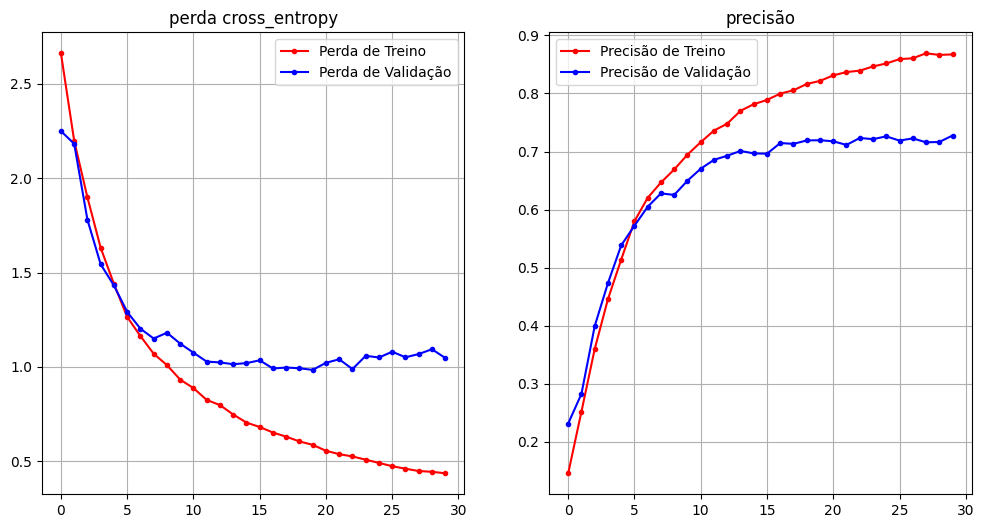

In [22]:
plot_loss_accuracy(history)

ta distanciando treino e val ainda, dá pra melhorar, mas eu ainda tenho o resto da atividade

## Exercício
### Sua Vez
- Construa uma rede neural com um SimpleRNN em vez de um LSTM (com outras dimensões e parâmetros iguais). Como o desempenho se compara?
- Use o LSTM acima sem os vetores de palavras pré-treinados (inicialize aleatoriamente os pesos e deixe-os serem aprendidos durante o processo de treinamento). Como o desempenho se compara?
- Experimente diferentes comprimentos de sequência e dimensões para o estado oculto do LSTM. Você consegue melhorar o modelo?

In [23]:
# Por favor, forneça seu código aqui

rnn = Sequential([
    Embedding(len(word_index) + 1,
              word_dimension,
              weights=[embedding_matrix],
              trainable=False),
    Dropout(0.3),
    SimpleRNN(128, kernel_initializer=RandomNormal(stddev=0.001),
                    recurrent_initializer=Identity(gain=1.0),
                    activation='relu'),
    Dropout(0.3),
    Dense(20, activation='softmax')])


acredito que 128 seja mt pro rnn, vou deixar 80, já que na rnn
não tem a concatenação de contexto e entrada

In [24]:
adam2 = Adam(learning_rate=.001, weight_decay=.01, clipnorm=1.0)

rnn.compile(loss='categorical_crossentropy',
                  optimizer=adam2,
                  metrics=['accuracy'])
print("\n")

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history_rnn = rnn.fit(x_train, y_train,
                            batch_size=batch_size,
                            epochs=30,
                            validation_data=(x_test, y_test),
                            callbacks=[early_stop])



Epoch 1/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.1381 - loss: 3.3625 - val_accuracy: 0.1950 - val_loss: 2.3497
Epoch 2/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.2231 - loss: 3.3995 - val_accuracy: 0.2853 - val_loss: 2.1339
Epoch 3/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.2712 - loss: 2.1825 - val_accuracy: 0.3173 - val_loss: 1.9938
Epoch 4/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.3197 - loss: 822.4430 - val_accuracy: 0.3289 - val_loss: 2.1210
Epoch 5/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.3583 - loss: 1.9196 - val_accuracy: 0.3793 - val_loss: 1.8364
Epoch 6/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.3877 - loss: 1.8974 - val_accuracy: 0.4234 - val_loss: 1.7009
Epoch 7/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.3999 - loss: 1.7820 - val_accuracy: 0.4122 - val_loss: 1.7324
Epoch 8/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.4244 - loss: 1.9978 - val

118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5190 - loss: 1.4606
perda no teste: 1.4606 , acurácia no teste: 0.5190


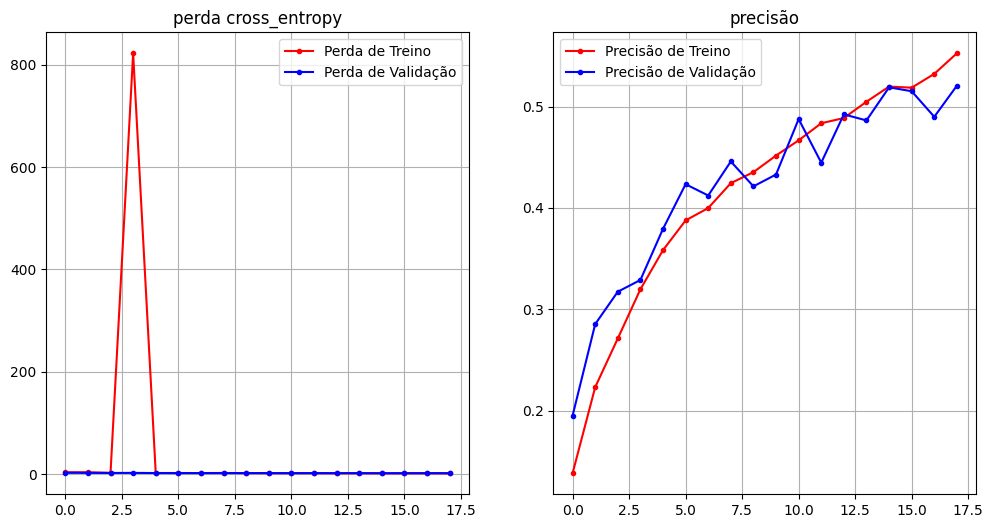

In [25]:
loss_rnn, acc_rnn = rnn.evaluate(x_test, y_test, batch_size=batch_size)
print(f"perda no teste: {loss_rnn:.4f} , acurácia no teste: {acc_rnn:.4f}")
plot_loss_accuracy(history_rnn)

In [26]:
rnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 150, 100)       │    13,414,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 150, 100)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        29,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,509,978 (51.54 MB)

 Trainable params: 31,892 (124.58 KB)

 Non-trainable params: 13,414,300 (51.17 MB)

 Optimizer params: 63,786 (249.17 KB)

com muito esforço, usando adam, técnicas de inicialização, a rnn chegou proximo de 55% de acurácia. o lstm chegou a ~75%. como foi mostrado em aula e no gráfico do loss, a rnn sofre com sequencias longas, pois as multiplicações matriciais em sequencia podem explodir o gradiente, causando o grande pico de loss no gráfico, além de instabilidade no treino. isso evidencia a premissa da lstm.

In [78]:
# treinando os embeddings juntos

lstm_embedding = Sequential([
    Embedding(10001, 50,
              trainable=True,
              embeddings_regularizer=l2(1e-3)),
    Dropout(0.5),
    LSTM(80, recurrent_regularizer=l2(1e-3)),
    Dropout(0.5),
    Dense(20, activation='softmax')
])

adam3 = Adam(learning_rate=.0005, weight_decay=.01, clipnorm=1.0)

lstm_embedding.compile(optimizer=adam3, loss='categorical_crossentropy', metrics=['accuracy'])


In [79]:
early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)

history3 = lstm_embedding.fit(x_train, y_train,
                            batch_size=batch_size,
                            epochs=30,
                            validation_data=(x_test, y_test),
                            callbacks=[early_stop])

Epoch 1/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.0706 - loss: 3.1049 - val_accuracy: 0.1113 - val_loss: 3.0030
Epoch 2/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.1196 - loss: 2.7961 - val_accuracy: 0.1547 - val_loss: 2.5771
Epoch 3/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.1711 - loss: 2.4806 - val_accuracy: 0.1818 - val_loss: 2.4640
Epoch 4/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.2168 - loss: 2.2957 - val_accuracy: 0.2130 - val_loss: 2.3544
Epoch 5/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.2599 - loss: 2.1274 - val_accuracy: 0.2711 - val_loss: 2.2325
Epoch 6/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.2930 - loss: 2.0037 - val_accuracy: 0.2910 - val_loss: 2.2088
Epoch 7/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.3232 - loss: 1.9274 - val_accuracy: 0.2841 - val_loss: 2.2444
Epoch 8/30
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.3613 - loss: 1.8514 - val_accu

In [80]:
lstm_embedding.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ (None, 150, 50)        │       500,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 150, 50)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 80)             │        41,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 80)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 20)             │         1,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,630,772 (6.22 MB)

 Trainable params: 543,590 (2.07 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,087,182 (4.15 MB)

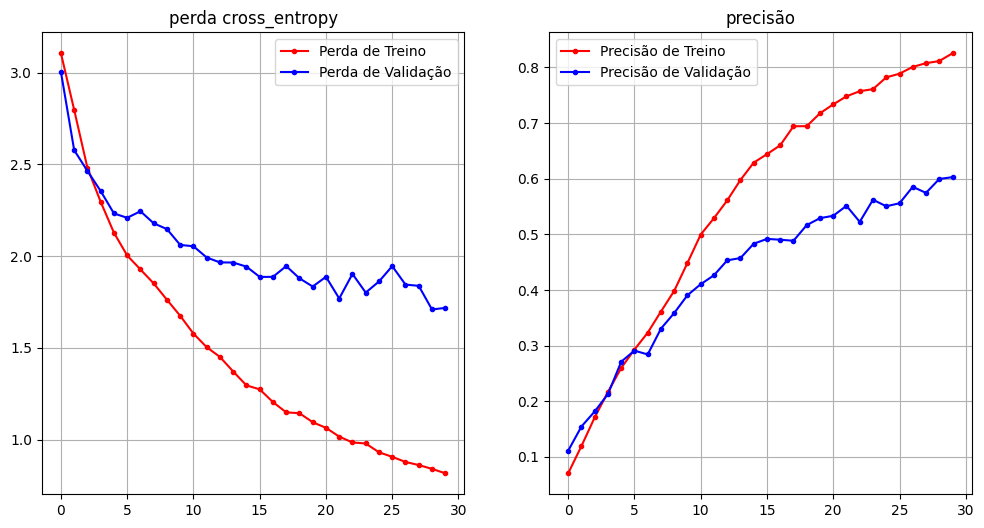

In [81]:
plot_loss_accuracy(history3)

In [82]:
loss_lstm, acc_lstm = lstm_embedding.evaluate(x_test, y_test, batch_size=batch_size)
print(f"perda no teste: {loss_lstm:.4f} , acurácia no teste: {acc_lstm:.4f}")

118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5994 - loss: 1.7095
perda no teste: 1.7095 , acurácia no teste: 0.5994


ok, inicialmente, overffiting claro. mas aparenta ainda permitir treinamento, pelas curvas do treinamento. vou tentar aumentar o dropout pra 0.5, no momento estava 0.3, e vou por earlystop pra não treinar a toa.
ok, aumentar o dropout não mudou muito.<br>
Vou fazer as seguintes mudanças: diminuir o peso dos embeddings, diminuindo o tamanho dos vetores e o a quantidade. o tokenizer tem 113k palavras, mas limitamos ele a 20k, e os embeddings do GloVe são feitos na wikipedia, faz sentido eles terem essa dimensão, mas estamos bem mais limitados e tendo uma matriz de embedding imensa em que a maioria não é usada. vou limitar a max_features e por a saida com 75, e por regularizadores l2<br>
Diminuiu o overffiting, mas não o suficiente. vou baixar a saida dos embeddings.
EU TINHA ESQUECIDO DE TIRAR OS UNITS DO LSTM... vou ver como fica com as mudanças que ja falei, tambem vou aumentar o l2, o overffiting ainda existe, mas diminuiu e demorou mais pra aparecer, estou com uma acurácia de ~42%. minha ultima tentativa vai ser diminuir max features pra 1000, mas já da pra tirar uma conclusção disso, temos poucos textos no train, montar os embeddings com 11k textos é difícil, pela falta de dados o modelo decora.
a acurácia aumentou, o loss diminuiu, mesmo com 60% de acc, não é o mesmo que os com embeddings prontos